In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

df = pd.read_csv(r'C:\Users\tchin\Downloads\tchin-covid-sir-model\data\raw\total_cases.csv')
df['date'] = pd.to_datetime(df['date'])

df
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,1674,2022-04-20 12:00:00,2020-01-05 00:00:00,2021-02-26 06:00:00,2022-04-20 12:00:00,2023-06-12 18:00:00,2024-08-04 00:00:00,NaN
World,1674.0,427537145.818996,2.0,110747235.0,503419024.0,766875788.0,775866783.0,308144071.644467
Afghanistan,1674.0,146946.822581,0.0,55604.0,178387.0,222526.0,235214.0,81976.948732
Africa,1674.0,8731712.125448,0.0,3849558.0,12007437.0,13096529.0,13145380.0,5079790.032019
Albania,1674.0,212446.273596,0.0,97909.0,274376.0,334090.0,335047.0,131691.259872
...,...,...,...,...,...,...,...,...
Vietnam,1674.0,6122353.31601,0.0,2383.0,10432547.0,11617497.0,11624000.0,5524284.755551
Wallis and Futuna,1674.0,1570.221027,0.0,9.0,454.0,3550.0,3760.0,1615.315112
Yemen,1674.0,8347.242533,0.0,2161.0,11817.0,11945.0,11945.0,4599.956807
Zambia,1674.0,223197.807646,0.0,73894.0,318467.0,345058.0,349842.0,141694.818042


In [2]:
def sir_model(t, y, beta, gamma):
    S, I, R = y
    dSdt = -beta * S * I
    dIdt = beta * S * I - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]

sol = solve_ivp(sir_model, (0, 160), [0.99, 0.01, 0], args=(0.3, 0.1), t_eval=np.linspace(0, 160, 160))
sol_df = pd.DataFrame(sol.y.T, columns=['S', 'I', 'R'])

sol_df

,S,I,R
0,0.990000,0.010000,0.000000
1,0.986701,0.012187,0.001113
2,0.982697,0.014835,0.002468
3,0.977849,0.018034,0.004117
4,0.971991,0.021890,0.006120
...,...,...,...
155,0.058304,0.000015,0.941681
156,0.058304,0.000014,0.941682
157,0.058303,0.000013,0.941683
158,0.058303,0.000012,0.941685


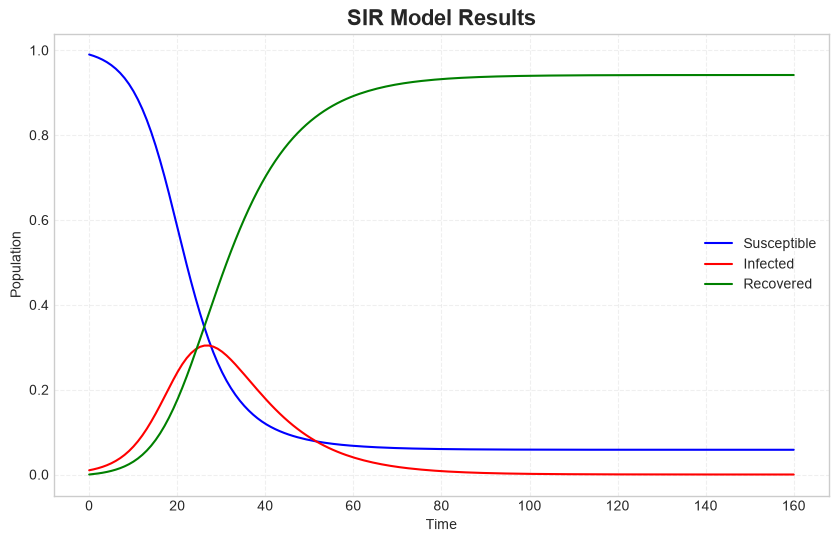

In [3]:
# Plot global SIR model results
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.figure(figsize=(10, 6))
plt.plot(sol.t, sol_df['S'], label='Susceptible', color='blue')
plt.plot(sol.t, sol_df['I'], label='Infected', color='red')
plt.plot(sol.t, sol_df['R'], label='Recovered', color='green')
plt.xlabel('Time')
plt.ylabel('Population')
plt.title('SIR Model Results', fontsize=16, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3, linestyle='--')
plt.show()